# PS-Q2: Quantum Kernel Estimator & SVM (QSVM): Processor A vs Processor B
End-to-end reproducible experiment. Run all cells from the project root (`Kernel > Restart & Run All`).

* Fidelity kernel `K(x,x') = |<phi(x)|phi(x')>|^2` on a **4-qubit register**
* Classical SVM trained on the precomputed quantum kernel
* Kernel-evaluation cost compared on **Processor A** (5 qubits, linear chain) vs **Processor B** (9 qubits, heavy-hex-inspired)
* Identical noise on both (p1 = 0.001, p2 = 0.005, readout = 0.01), optimization level 1, seed 42, 4096 shots

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.problem import (generate_dataset, feature_map, make_fidelity_circuit, ideal_kernel_matrix,
                         train_precomputed_svm, rbf_baseline, N_QUBITS)
from src.processors import load_processor, native_ring_edges
from src.metrics import compilation_table, benchmark_kernel_cost
from src.visualization import (draw_coupling_graph, plot_dataset, plot_kernel_heatmap,
                               plot_cost_comparison, plot_routing_overhead, render_equation)

SEED = 42
N_BENCH_PAIRS = 30
TABLES, FIGS = Path("results/tables"), Path("results/figures")
RAW, PROC = Path("data/raw"), Path("data/processed")
for d in (TABLES, FIGS, RAW, PROC): d.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)

## 1. Processors A and B

Processor A: 5 qubits, 4 edges, layout [0, 1, 2, 3], native ring edges 3/4, noise p1=0.001 p2=0.005 ro=0.01, opt=1, seed=42, shots=4096
Processor B: 9 qubits, 12 edges, layout [0, 1, 6, 8], native ring edges 4/4, noise p1=0.001 p2=0.005 ro=0.01, opt=1, seed=42, shots=4096


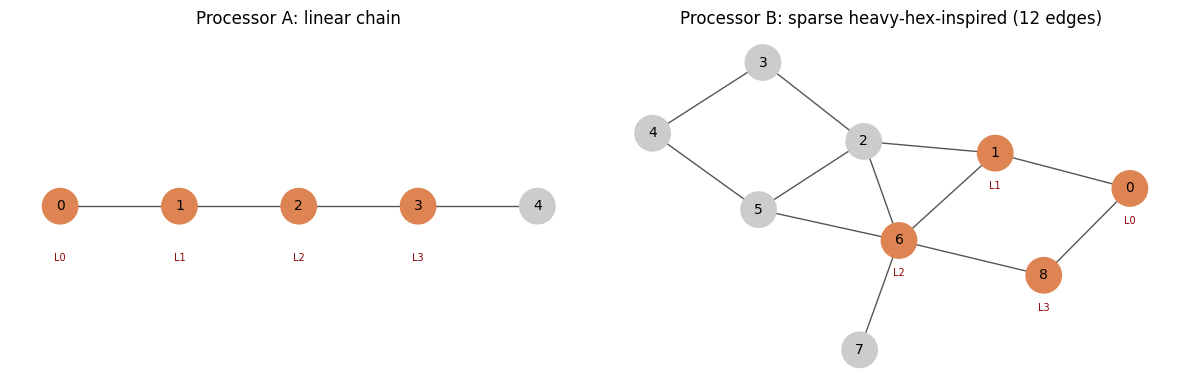

In [2]:
proc_A = load_processor("processors/processor_A.json")
proc_B = load_processor("processors/processor_B.json")
PROCS = [proc_A, proc_B]

for p in PROCS:
    ok, tot = native_ring_edges(p)
    print(f"{p.name}: {p.n_qubits} qubits, {len(p.edges)} edges, layout {p.layout}, "
          f"native ring edges {ok}/{tot}, noise p1={p.p1} p2={p.p2} ro={p.p_readout}, "
          f"opt={p.optimization_level}, seed={p.seed_transpiler}, shots={p.shots}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
draw_coupling_graph(proc_A, ax[0]); draw_coupling_graph(proc_B, ax[1])
fig.tight_layout(); fig.savefig(FIGS / "coupling_graphs.png", dpi=200); plt.show()

## 2. Dataset: `make_moons(n_samples=100, noise=0.1, random_state=42)`

Train: (80, 2) | Test: (20, 2)


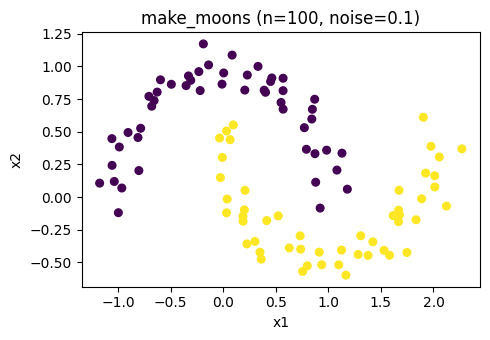

In [3]:
data = generate_dataset(n_samples=100, noise=0.1, seed=SEED, test_size=0.2)
X_train, X_test = data["X_train"], data["X_test"]
y_train, y_test = data["y_train"], data["y_test"]

# raw generated inputs and processed (scaled, split) arrays
np.save(RAW / "moons_X.npy", data["X"]); np.save(RAW / "moons_y.npy", data["y"])
pd.DataFrame({"x1": data["X"][:, 0], "x2": data["X"][:, 1], "label": data["y"]}).to_csv(RAW / "moons.csv", index=False)
for k in ("X_train", "X_test", "y_train", "y_test"): np.save(PROC / f"{k}.npy", data[k])

print("Train:", X_train.shape, "| Test:", X_test.shape)
plot_dataset(data["X"], data["y"], FIGS / "dataset_moons.png"); plt.show()

## 3. Ideal fidelity kernel and SVM

     ┌───┐┌─────────────┐                                                                        ┌───┐┌────────────┐»
q_0: ┤ H ├┤ Rz(0.29081) ├──■──────────────────■──────────────────────────────────────────────────┤ X ├┤ Rz(7.2125) ├»
     ├───┤└┬───────────┬┘┌─┴─┐┌────────────┐┌─┴─┐                                                └─┬─┘└────────────┘»
q_1: ┤ H ├─┤ Rz(3.876) ├─┤ X ├┤ Rz(7.2125) ├┤ X ├──■──────────────────■────────────────────────────┼────────────────»
     ├───┤┌┴───────────┴┐└───┘└────────────┘└───┘┌─┴─┐┌────────────┐┌─┴─┐                          │                »
q_2: ┤ H ├┤ Rz(0.29081) ├────────────────────────┤ X ├┤ Rz(7.2125) ├┤ X ├──■──────────────────■────┼────────────────»
     ├───┤└┬───────────┬┘                        └───┘└────────────┘└───┘┌─┴─┐┌────────────┐┌─┴─┐  │                »
q_3: ┤ H ├─┤ Rz(3.876) ├─────────────────────────────────────────────────┤ X ├┤ Rz(7.2125) ├┤ X ├──■────────────────»
     └───┘ └───────────┘                                

                        Accuracy  Precision  Recall      F1
Quantum kernel (ideal)      0.95        1.0     0.9  0.9474
Classical RBF baseline      0.90        1.0     0.8  0.8889


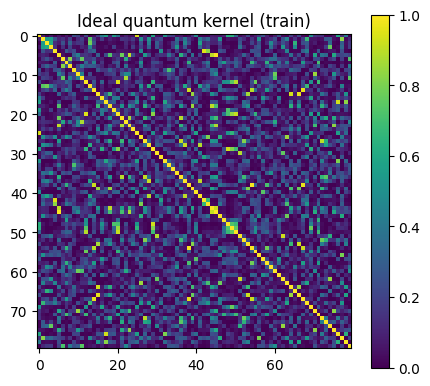

In [4]:
print(feature_map(X_train[0]).draw(fold=120))

K_train = ideal_kernel_matrix(X_train, X_train)
K_test  = ideal_kernel_matrix(X_test, X_train)
np.save(PROC / "K_train_ideal.npy", K_train); np.save(PROC / "K_test_ideal.npy", K_test)

svm, pred, m_q = train_precomputed_svm(K_train, K_test, y_train, y_test)
m_rbf = rbf_baseline(X_train, X_test, y_train, y_test)
svm_table = pd.DataFrame({"Quantum kernel (ideal)": m_q, "Classical RBF baseline": m_rbf}).T
svm_table.to_csv(TABLES / "svm_results.csv"); svm_table.round(4).to_json(TABLES / "svm_results.json", indent=2)
print(svm_table.round(4).to_string())
plot_kernel_heatmap(K_train, "Ideal quantum kernel (train)", FIGS / "kernel_train_ideal.png"); plt.show()

## 4. Compilation analysis (A vs B)

                Target  Depth  Total ops  CX  Routing CX overhead  Est. SWAPs (overhead/3)
All-to-all (reference)     28         49  14                    0                 0.000000
           Processor A     35         59  24                   10                 3.333333
           Processor B     28         49  14                    0                 0.000000


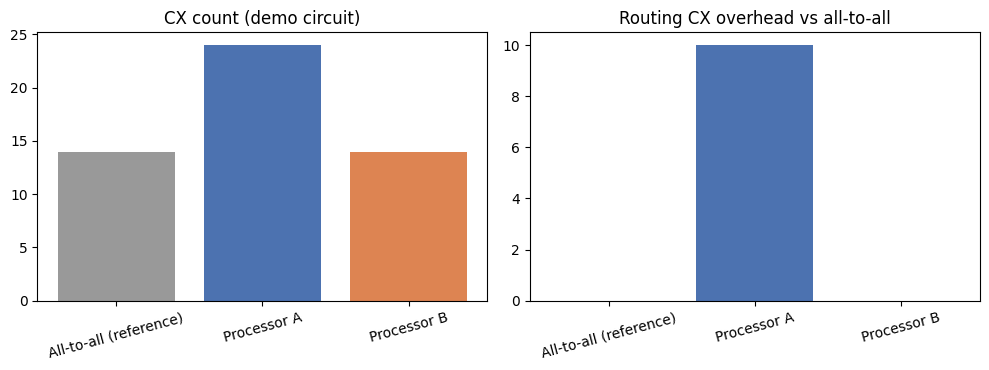

In [5]:
qc_demo = make_fidelity_circuit(X_train[0], X_train[1])
compilation = compilation_table(qc_demo, PROCS)
compilation.to_csv(TABLES / "compilation_results.csv", index=False)
compilation.round(2).to_json(TABLES / "compilation_results.json", orient="records", indent=2)
print(compilation.to_string(index=False))
plot_routing_overhead(compilation, FIGS / "routing_overhead.png"); plt.show()

## 5. Kernel-evaluation cost benchmark (same random pairs on A and B)

Processor                      Processor A   Processor B
Physical qubits               5.000000e+00  9.000000e+00
Pairs benchmarked             3.000000e+01  3.000000e+01
Mean depth                    3.476667e+01  2.770000e+01
Mean total ops                5.876667e+01  4.870000e+01
Mean CX gates                 2.386667e+01  1.380000e+01
Mean compile time (s)         4.652087e-03  4.936627e-03
Mean execution time (s)       1.177355e-02  1.121405e-02
Mean time / evaluation (s)    1.642564e-02  1.615068e-02
Kernel entries needed (sym.)  4.840000e+03  4.840000e+03
Est. total time (s)           7.950010e+01  7.816928e+01
Total shots needed            1.982464e+07  1.982464e+07
Mean |noisy - ideal|          2.112404e-02  1.676206e-02
Max |noisy - ideal|           1.156727e-01  8.881721e-02
Mean binomial std. error      4.063621e-03  4.067468e-03


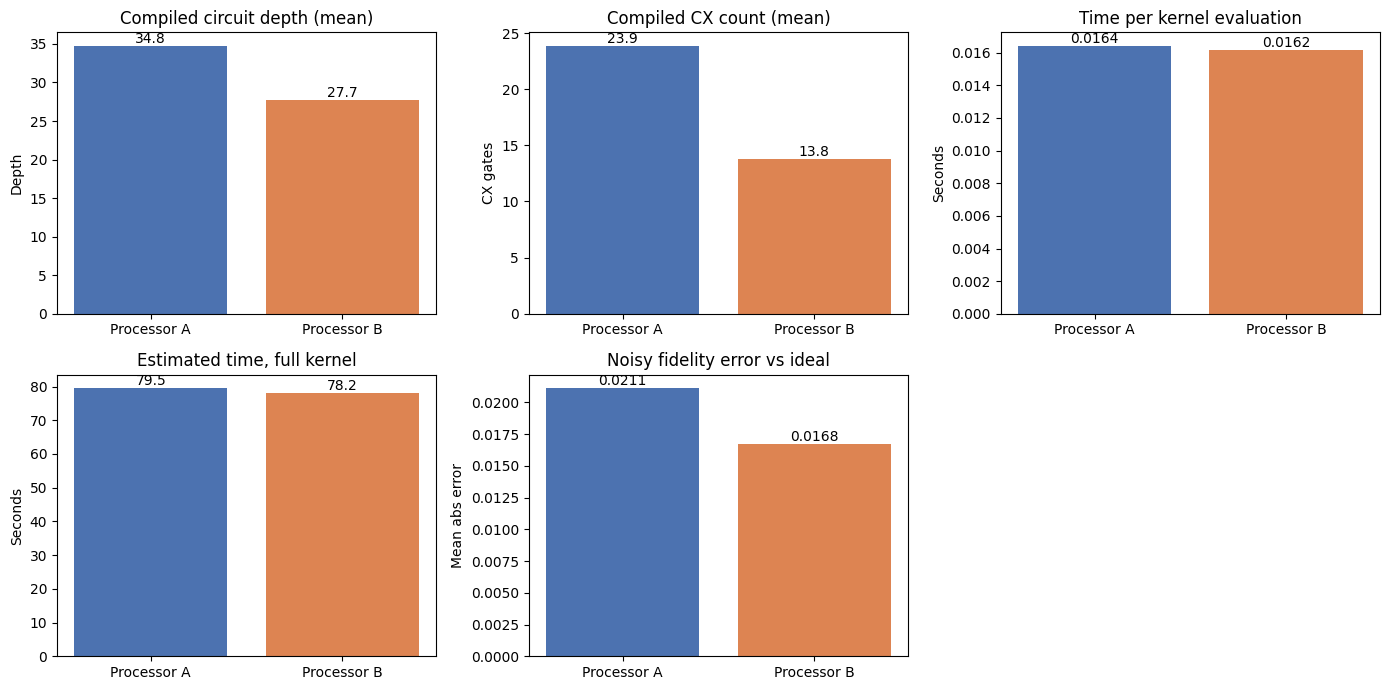

In [6]:
rows = [benchmark_kernel_cost(p, X_train, n_test=len(X_test), n_pairs=N_BENCH_PAIRS, seed=SEED) for p in PROCS]
cost = pd.DataFrame(rows)
cost.to_csv(TABLES / "kernel_evaluation_cost.csv", index=False)
cost.to_json(TABLES / "kernel_evaluation_cost.json", orient="records", indent=2)
print(cost.set_index("Processor").T.to_string())
plot_cost_comparison(cost, FIGS / "cost_comparison.png"); plt.show()

## 6. Equation assets (for README / report)

In [7]:
EQ = Path("assets/qff_phase1_latex_images"); EQ.mkdir(parents=True, exist_ok=True)
equations = {
    "eq_qubit_state":    r"|\psi\rangle = \alpha|0\rangle + \beta|1\rangle,\ |\alpha|^2+|\beta|^2=1",
    "eq_bell_state":     r"|\Phi^+\rangle = \frac{1}{\sqrt{2}}\left(|00\rangle + |11\rangle\right)",
    "eq_graph":          r"G=(V,E),\ V=\{0,\ldots,n-1\},\ E\subseteq V\times V",
    "eq_bell_fidelity":  r"F = \langle\Phi^+|\rho|\Phi^+\rangle",
    "eq_zz_expectation": r"\langle Z_iZ_j\rangle = P(00)+P(11)-P(01)-P(10)",
    "eq_standard_error": r"\mathrm{SE}=\sqrt{\frac{\hat p(1-\hat p)}{N_{\mathrm{shots}}}}",
    "eq_fidelity_kernel": r"K(x,x') = |\langle\phi(x)|\phi(x')\rangle|^2 = P(0000)\ \mathrm{of}\ U(x')^\dagger U(x)|0000\rangle",
}
for name, tex in equations.items(): render_equation(tex, EQ / f"{name}.png")
print("Rendered:", sorted(p.name for p in EQ.glob("*.png")))

Rendered: ['eq_bell_fidelity.png', 'eq_bell_state.png', 'eq_fidelity_kernel.png', 'eq_graph.png', 'eq_qubit_state.png', 'eq_standard_error.png', 'eq_zz_expectation.png']


## 7. Summary

In [8]:
a, b = cost.iloc[0], cost.iloc[1]
print(f"Ideal-kernel QSVM accuracy : {m_q['Accuracy']:.3f}  (RBF baseline {m_rbf['Accuracy']:.3f})")
print(f"Mean CX / evaluation       : A = {a['Mean CX gates']:.1f} | B = {b['Mean CX gates']:.1f}")
print(f"Mean depth / evaluation    : A = {a['Mean depth']:.1f} | B = {b['Mean depth']:.1f}")
print(f"Time / evaluation (s)      : A = {a['Mean time / evaluation (s)']:.4f} | B = {b['Mean time / evaluation (s)']:.4f}")
print(f"Mean |noisy - ideal|       : A = {a['Mean |noisy - ideal|']:.4f} | B = {b['Mean |noisy - ideal|']:.4f}")
print(f"Mean binomial std. error   : A = {a['Mean binomial std. error']:.4f} | B = {b['Mean binomial std. error']:.4f}")

Ideal-kernel QSVM accuracy : 0.950  (RBF baseline 0.900)
Mean CX / evaluation       : A = 23.9 | B = 13.8
Mean depth / evaluation    : A = 34.8 | B = 27.7
Time / evaluation (s)      : A = 0.0164 | B = 0.0162
Mean |noisy - ideal|       : A = 0.0211 | B = 0.0168
Mean binomial std. error   : A = 0.0041 | B = 0.0041
